Q1. Write a unique paragraph (5-6 sentences) about your favorite topic (e.g., sports,
technology, food, books, etc.).
1. Convert text to lowercase and remove punctuation using re.
2. Tokenize the text into words and sentences.
3. Split using split() and word_tokenize() and compare how Python split and NLTK’s
word_tokenize() differ.
4. Remove stopwords (using NLTK's stopwords list).
5. Display word frequency distribu5on (excluding stopwords).

In [3]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import Counter
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

para="Have you ever wondered what would happen if the gods and humans had babies? Well, depending on their godly parent, they get powers and gifts. They become 'Demigods' or heroes. They're called heroes because they carry out deeds that the gods themselves can't. One such hero whose story is written by the famous author Rick Riorden, is Percy Jackson. In the books, we uncover the mysterious world beyond the 'mist'. The protagonists of the first book series are Percy Jackson, Annabeth Chase, and Grover Underwood."

#1
clean_text = re.sub(r'[^\w\s]', '', para.lower())
print("Cleaned Text:\n", clean_text)
#2
words = word_tokenize(clean_text)
sentences = sent_tokenize(para)
print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)
#3
print("\nUsing split():\n", para.split())
print("\nUsing word_tokenize():\n", word_tokenize(para))
#4
stop_words = set(stopwords.words('english'))
filtered_words = [
    word for word in words
    if word.isalpha() and word not in stop_words
]
print("\nWords after removing stopwords:\n", filtered_words)
#5
frequency = Counter(filtered_words)
print("\nWord Frequency Distribution:")
for word, count in frequency.most_common():
    print(word, ":", count)


Cleaned Text:
 have you ever wondered what would happen if the gods and humans had babies well depending on their godly parent they get powers and gifts they become demigods or heroes theyre called heroes because they carry out deeds that the gods themselves cant one such hero whose story is written by the famous author rick riorden is percy jackson in the books we uncover the mysterious world beyond the mist the protagonists of the first book series are percy jackson annabeth chase and grover underwood

Word Tokens:
 ['have', 'you', 'ever', 'wondered', 'what', 'would', 'happen', 'if', 'the', 'gods', 'and', 'humans', 'had', 'babies', 'well', 'depending', 'on', 'their', 'godly', 'parent', 'they', 'get', 'powers', 'and', 'gifts', 'they', 'become', 'demigods', 'or', 'heroes', 'theyre', 'called', 'heroes', 'because', 'they', 'carry', 'out', 'deeds', 'that', 'the', 'gods', 'themselves', 'cant', 'one', 'such', 'hero', 'whose', 'story', 'is', 'written', 'by', 'the', 'famous', 'author', 'rick'

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Q2. Using the same paragraph from Q1:
1. Extract all words with only alphabets using re.findall()
2. Remove stop words using NLTK’s stopword list
3. Perform stemming with PorterStemmer
4. Perform lemma5za5on with WordNetLemma5zer
5. Compare the stemmed and lemma5zed outputs and explain when you’d prefer one over
the other.

In [4]:
#1
words = re.findall(r'\b[a-zA-Z]+\b', para.lower())
print("Alphabetic words:\n", words)
#2
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]
print("\nAfter stopword removal:\n", filtered_words)
#3
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_words]
print("\nStemmed words:\n", stemmed_words)
#4
lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in filtered_words]
print("\nLemmatized words:\n", lemmatized_words)
#5
print("\nComparison:")
for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(f"{original:15} -> Stem: {stem:12} Lemma: {lemma}")

Alphabetic words:
 ['have', 'you', 'ever', 'wondered', 'what', 'would', 'happen', 'if', 'the', 'gods', 'and', 'humans', 'had', 'babies', 'well', 'depending', 'on', 'their', 'godly', 'parent', 'they', 'get', 'powers', 'and', 'gifts', 'they', 'become', 'demigods', 'or', 'heroes', 'they', 're', 'called', 'heroes', 'because', 'they', 'carry', 'out', 'deeds', 'that', 'the', 'gods', 'themselves', 'can', 't', 'one', 'such', 'hero', 'whose', 'story', 'is', 'written', 'by', 'the', 'famous', 'author', 'rick', 'riorden', 'is', 'percy', 'jackson', 'in', 'the', 'books', 'we', 'uncover', 'the', 'mysterious', 'world', 'beyond', 'the', 'mist', 'the', 'protagonists', 'of', 'the', 'first', 'book', 'series', 'are', 'percy', 'jackson', 'annabeth', 'chase', 'and', 'grover', 'underwood']

After stopword removal:
 ['ever', 'wondered', 'would', 'happen', 'gods', 'humans', 'babies', 'well', 'depending', 'godly', 'parent', 'get', 'powers', 'gifts', 'become', 'demigods', 'heroes', 'called', 'heroes', 'carry', 'd

Q3. Choose 3 short texts of your own (e.g., different news headlines, product reviews).
1. Use CountVectorizer to generate the Bag of Words representa5on.
2. Use TfidfVectorizer to compute TF-IDF scores.
3. Print and interpret the top 3 keywords from each text using TF-IDF.

In [5]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
texts = [
    "I study in Thapar Institute of Engineering and Technology.",
    "I am pursuing Engineering from Thapar Institure of Engineering and Technology.",
    "I am sitting in the Information and Technology Lab."
]

#1
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)
print("Bag of Words Vocabulary:")
print(count_vectorizer.get_feature_names_out())
print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

#2
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
features = tfidf_vectorizer.get_feature_names_out()
print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray())

#3
print("\nTop 3 TF-IDF Keywords:")
for i, row in enumerate(tfidf_matrix.toarray()):
    top_indices = row.argsort()[::-1][:3]
    keywords = [(features[j], round(row[j], 3))
                for j in top_indices if row[j] > 0]
    print(f"Text {i + 1}: {keywords}")


Bag of Words Vocabulary:
['am' 'and' 'engineering' 'from' 'in' 'information' 'institure'
 'institute' 'lab' 'of' 'pursuing' 'sitting' 'study' 'technology' 'thapar'
 'the']

Bag of Words Matrix:
[[0 1 1 0 1 0 0 1 0 1 0 0 1 1 1 0]
 [1 1 2 1 0 0 1 0 0 1 1 0 0 1 1 0]
 [1 1 0 0 1 1 0 0 1 0 0 1 0 1 0 1]]

TF-IDF Matrix:
[[0.         0.26383484 0.33973539 0.         0.33973539 0.
  0.         0.44671121 0.         0.33973539 0.         0.
  0.44671121 0.26383484 0.33973539 0.        ]
 [0.2732515  0.21220416 0.54650299 0.35929288 0.         0.
  0.35929288 0.         0.         0.2732515  0.35929288 0.
  0.         0.21220416 0.2732515  0.        ]
 [0.31431908 0.24409681 0.         0.         0.31431908 0.41329182
  0.         0.         0.41329182 0.         0.         0.41329182
  0.         0.24409681 0.         0.41329182]]

Top 3 TF-IDF Keywords:
Text 1: [('study', np.float64(0.447)), ('institute', np.float64(0.447)), ('of', np.float64(0.34))]
Text 2: [('engineering', np.float64(0.547))

Q4. Write 2 short texts (4–6 lines each) describing two different technologies (e.g., AI vs
Blockchain).
1. Preprocess and tokenize both texts.
2. Calculate:
a. Jaccard Similarity using sets
b. Cosine Similarity using TfidfVectorizer + cosine_similarity()
c. Analyze which similarity metric gives be^er insights in your case.

In [6]:

import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Two texts about different technologies
text1 = """Artificial intelligence enables machines to learn from data.
It helps computers recognize patterns and make predictions.
AI is used in healthcare, education, and transportation.
It can automate repetitive tasks and support decision-making.
AI systems improve through learning algorithms and training data."""

text2 = """Blockchain stores information in linked digital blocks.
It creates a distributed and transparent record of transactions.
Blockchain is used in digital currencies and supply chains.
It can improve security and data traceability.
Blockchain systems rely on cryptographic techniques and networks."""

#1
def preprocess(text):
    text = text.lower()
    return re.findall(r'\b[a-z]+\b', text)
tokens1 = preprocess(text1)
tokens2 = preprocess(text2)
set1 = set(tokens1)
set2 = set(tokens2)
print("Tokens in Text 1:\n", tokens1)
print("\nTokens in Text 2:\n", tokens2)

#2(a)
intersection = set1.intersection(set2)
union = set1.union(set2)
jaccard = len(intersection) / len(union)
print("\nCommon words:", intersection)
print("Jaccard Similarity:", round(jaccard, 4))

#2(b)
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform([text1, text2])
cosine = cosine_similarity(
    tfidf_matrix[0:1], tfidf_matrix[1:2]
)[0][0]
print("Cosine Similarity:", round(cosine, 4))

#2(c)
print("\nAnalysis:")
print("Jaccard measures overlap between unique words.")
print("Cosine measures similarity between TF-IDF vectors.")
print("Higher similarity means greater similarity between texts.")


Tokens in Text 1:
 ['artificial', 'intelligence', 'enables', 'machines', 'to', 'learn', 'from', 'data', 'it', 'helps', 'computers', 'recognize', 'patterns', 'and', 'make', 'predictions', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'transportation', 'it', 'can', 'automate', 'repetitive', 'tasks', 'and', 'support', 'decision', 'making', 'ai', 'systems', 'improve', 'through', 'learning', 'algorithms', 'and', 'training', 'data']

Tokens in Text 2:
 ['blockchain', 'stores', 'information', 'in', 'linked', 'digital', 'blocks', 'it', 'creates', 'a', 'distributed', 'and', 'transparent', 'record', 'of', 'transactions', 'blockchain', 'is', 'used', 'in', 'digital', 'currencies', 'and', 'supply', 'chains', 'it', 'can', 'improve', 'security', 'and', 'data', 'traceability', 'blockchain', 'systems', 'rely', 'on', 'cryptographic', 'techniques', 'and', 'networks']

Common words: {'used', 'is', 'improve', 'can', 'systems', 'and', 'in', 'it', 'data'}
Jaccard Similarity: 0.1525
Cosine Simil

Q5. Write a short review for a product or service.
1. Use TextBlob or VADER to find polarity & subjec5vity for each review.
2. Classify reviews into Positive / Negative / Neutral.
3. Create a word cloud using the wordcloud library for all posi5ve reviews.


Review 1: This laptop is excellent and works very smoothly.
Polarity: 0.76
Subjectivity: 0.825
Sentiment: Positive

Review 2: The battery life is amazing and the screen is beautiful.
Polarity: 0.725
Subjectivity: 0.95
Sentiment: Positive

Review 3: I am very happy with this product.
Polarity: 1.0
Subjectivity: 1.0
Sentiment: Positive

Review 4: The laptop is slow and the battery is terrible.
Polarity: -0.65
Subjectivity: 0.7
Sentiment: Negative

Review 5: Poor quality and disappointing performance.
Polarity: -0.5
Subjectivity: 0.65
Sentiment: Negative

Review 6: The product is okay and works as expected.
Polarity: 0.2
Subjectivity: 0.45
Sentiment: Positive


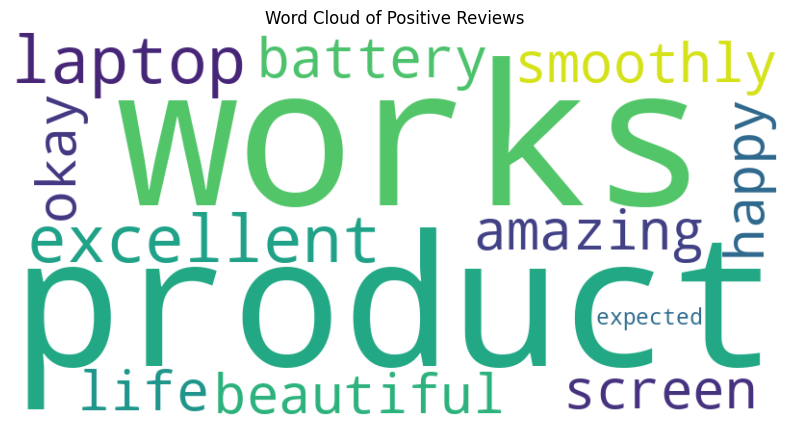

In [7]:

from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This laptop is excellent and works very smoothly.",
    "The battery life is amazing and the screen is beautiful.",
    "I am very happy with this product.",
    "The laptop is slow and the battery is terrible.",
    "Poor quality and disappointing performance.",
    "The product is okay and works as expected."
]
positive_reviews = []

#1 & 2
for i, review in enumerate(reviews, start=1):
    analysis = TextBlob(review)
    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity
    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"
    print(f"\nReview {i}: {review}")
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)

#3
if positive_reviews:
    positive_text = " ".join(positive_reviews)
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        stopwords=None
    ).generate(positive_text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews available for the word cloud.")


Q6. Choose your own paragraph (~100 words) as training data.
1. Tokenize text using Tokenizer() from keras.preprocessing.text
2. Create input sequences and build a simple LSTM or Dense model
3. Train the model and generate 2–3 new lines of text star5ng from any seed word you
provide.

In [9]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

#1
text = """
Percy Jackson and the Olympians, also known as PJO, is a fantasy series about Greek mythology, demigods, monsters, gods, and adventures.
Percy Jackson is a demigod who discovers that his father is Poseidon, the Greek god of the sea.
His life changes completely after he discovers the truth about his family and the world of Greek mythology.
Percy goes to Camp Half-Blood, a camp where demigods learn about their powers, train to fight monsters, and meet other demigods like themselves.
At Camp Half-Blood, Percy meets Annabeth Chase, a daughter of Athena who is intelligent, brave, and always ready with a plan.
He also meets Grover Underwood, his best friend, who is a satyr and cares deeply about protecting his friends.
Percy, Annabeth, and Grover go on many adventures together, and every adventure brings new challenges, new monsters, and new secrets.
The gods are powerful, but the gods are not always fair, and their decisions often create problems for the demigods.
Percy has to deal with difficult prophecies, dangerous enemies, and complicated relationships between the gods.
Even when things become difficult, Percy continues to fight for his friends and for the people he cares about.
Annabeth uses her intelligence to help the group, Grover uses his loyalty and courage to support his friends, and Percy uses his determination to overcome challenges.
The friendship between Percy, Annabeth, and Grover is one of the most important parts of the story because they learn to trust each other and work together.
PJO is full of action, humor, friendship, loyalty, and mythology, which makes the story exciting and memorable.
The series shows that being a hero is not only about having powers or defeating monsters, but also about making difficult choices, protecting friends, and doing the right thing.
Percy Jackson and the Olympians remains an enjoyable story because it combines ancient Greek mythology with modern life, relatable characters, funny moments, and exciting adventures.
"""

#2
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])
total_words = len(tokenizer.word_index) + 1
sequences = []
for line in text.strip().split("\n"):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(2, len(token_list) + 1):
        sequences.append(token_list[:i])
max_sequence_len = max(len(seq) for seq in sequences)
sequences = pad_sequences(
    sequences,
    maxlen=max_sequence_len,
    padding="pre"
)
X = sequences[:, :-1]
y = sequences[:, -1]
print("Vocabulary size:", total_words)
print("Number of training sequences:", len(X))
print("Input shape:", X.shape)
print("Target shape:", y.shape)

#3
model = Sequential([
    Embedding(
        input_dim=total_words,
        output_dim=32,
        input_length=max_sequence_len - 1
    ),
    LSTM(64),
    Dense(total_words, activation="softmax")
])
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)
model.summary()

#4
model.fit(X, y, epochs=150, verbose=0)
print("\nModel training completed.")

#5
def generate_text(seed_text, next_words=8):
    output_text = seed_text
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences(
            [output_text]
        )[0]
        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding="pre"
        )
        predictions = model.predict(token_list, verbose=0)[0]
        predicted_index = int(np.argmax(predictions))
        if predicted_index == 0:
            break
        output_word = tokenizer.index_word.get(predicted_index)
        if output_word is None:
            break
        output_text += " " + output_word
    return output_text

for seed in ["Percy", "Annabeth", "adventure"]:
    print("\nGenerated text:")
    print(generate_text(seed, next_words=8))


Vocabulary size: 161
Number of training sequences: 305
Input shape: (305, 28)
Target shape: (305,)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Model training completed.

Generated text:
Percy jackson and the olympians remains an enjoyable story

Generated text:
Annabeth and grover go on many adventures together and

Generated text:
adventure when things become difficult percy continues to fight
